# 04 群の「悪さ」の 3 つの見方

01〜03 の結果を、群の悪さの 3 つの見方で並べ直し、報告用の図を作る。新しい学習はしない。

| 見方 | 何を見るか | 物差し |
|---|---|---|
| 動作点 | 得点がしきい値 0.5 のどちら側にあるか。陽性率で大きく動く | 0.5 の FPR（CheXpert では見落とし） |
| 較正 | 同じ得点の画像で、実際の陽性率が群によって違うか | 再較正した確率に対する陽性数の log O/E |
| 判別 | 群の中で、陽性と陰性を得点で分けられているか | 群の AUROC − 補集合の AUROC |

- 対象：01〜03 と同じ（CheXpert race-known、1 段・ERM の Spatial LoRA、seed 42・43・44、best val AUROC）
- 群は val で作り、各見方の物差しで val で最悪の群を選び、test で測る
- 判別の AUROC は、得点の幅が狭い群ほど低く出る（得点の低い側に偏った群など）。ここでは補正しない

図は `figures/04_three_lenses/`、表は `results/04_three_lenses/` に置く。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rootutils
import umap
from matplotlib.lines import Line2D
from scipy.special import expit
from sklearn.metrics import roc_auc_score

ROOT = rootutils.setup_root(Path.cwd(), indicator=".project-root", pythonpath=True)
from analysis.common.paths import STYLE_SHEET, study_dir  # noqa: E402
from analysis.latent_subgroup_spaces import subgroups as sg  # noqa: E402

plt.style.use(STYLE_SHEET)
PACKAGE = study_dir("latent_subgroup_spaces")
TOPIC = "04_three_lenses"
RESULTS = PACKAGE / "results" / TOPIC
FIGURES = PACKAGE / "figures" / TOPIC
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

RUNS = {
    42: "20261002T125005Z-spatial-lora-chexpert-race-known-s42-a21c",
    43: "20261002T145233Z-spatial-lora-chexpert-race-known-s43-424e",
    44: "20261002T165551Z-spatial-lora-chexpert-race-known-s44-eb13",
}
K_CLUSTER = 8
RIDGE_BINS = 8
# LHCF の K は 02 の BIC で選んだ値（3 seed とも特徴 12、RAD-DINO 11）。
LHCF_K = {"feat32": 12, "rad32": 11}
NULL_DRAWS = 200

# 図の色（Okabe-Ito）。属性だけの空間と、画像を見る空間で分ける。
ATTRIBUTE_SPACE = "#0072B2"
IMAGE_SPACE = "#D55E00"
NEUTRAL = "0.55"
POSITIVE = "#009E73"
NEGATIVE = "#CC79A7"
SLIDE_WIDTH = 9.0  # スライドの図の幅（inch）

/home/akiba/workspace/hypernet-fairness/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 読み込み

run ごとに val・test の得点・特徴・RAD-DINO と各空間の座標を作り、val 全体で得点を再較正する（03 と同じ）。

In [2]:
DATA, SPACES, PROB = {}, {}, {}
for seed, run_id in RUNS.items():
    DATA[seed], SPACES[seed] = sg.build_spaces(run_id)
    PROB[seed] = sg.recalibrate(DATA[seed]["val"].frame, DATA[seed]["test"].frame)
{seed: (len(d["val"].frame), len(d["test"].frame)) for seed, d in DATA.items()}

{42: (20058, 19617), 43: (20058, 19617), 44: (20058, 19617)}

## 図 1：3 つの見方の模式図

実データだと説明が濁るので、人工データで描く。

- (a) 動作点：2 つの群は較正も判別も同じで、陽性率だけが違う。陽性率の高い群は得点が全体に上がり、陰性も 0.5 を超えやすい
- (b) 較正：同じ得点でも、群では実際の陽性率が低い
- (c) 判別：群の中では陽性と陰性の得点分布が重なる

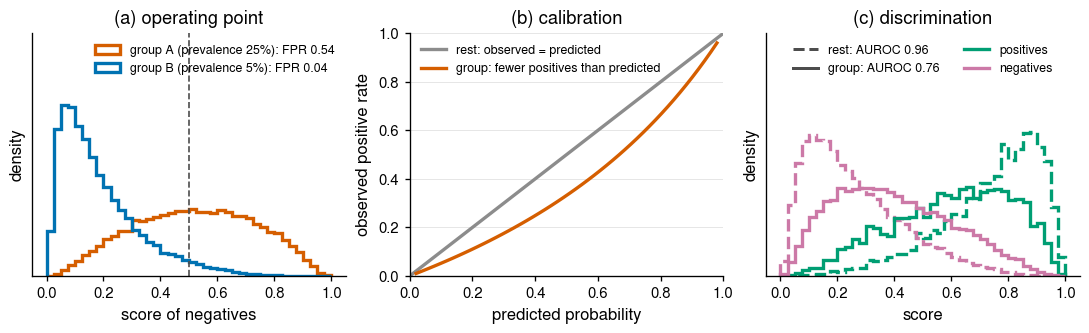

In [3]:
TOY_BASE_PREVALENCE = 0.10  # 全体の陽性率。inverse class weight で学習した得点は、全体では陽性・陰性が 0 を挟んで対称になる


def toy_scores(rng, n, prevalence, separation):
    """logit 上で陽性・陰性を ±separation/2 に置き、群の陽性率と全体の陽性率の対数オッズの差を切片に足した得点。"""
    y = rng.random(n) < prevalence
    shift = np.log(prevalence / (1 - prevalence)) - np.log(TOY_BASE_PREVALENCE / (1 - TOY_BASE_PREVALENCE))
    logit = np.where(y, separation / 2, -separation / 2) + rng.normal(0, 1, n) + shift
    return y, expit(logit)


def draw_toy(path):
    rng = np.random.default_rng(0)
    fig, axes = plt.subplots(1, 3, figsize=(SLIDE_WIDTH, 2.7))
    bins = np.linspace(0, 1, 41)

    ax = axes[0]
    for prevalence, color, label in ((0.25, IMAGE_SPACE, "group A (prevalence 25%)"), (0.05, ATTRIBUTE_SPACE, "group B (prevalence 5%)")):
        y, p = toy_scores(rng, 40000, prevalence, 2.0)
        fpr = (p[~y] >= 0.5).mean()
        ax.hist(p[~y], bins=bins, density=True, histtype="step", lw=2, color=color, label=f"{label}: FPR {fpr:.2f}")
    ax.axvline(0.5, color="0.3", lw=1, ls="--")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.35)
    ax.set(title="(a) operating point", xlabel="score of negatives", ylabel="density", yticks=[])
    ax.legend(loc="upper right", frameon=False, fontsize=7.5)

    ax = axes[1]
    grid = np.linspace(0.02, 0.98, 50)
    ax.plot([0, 1], [0, 1], color=NEUTRAL, lw=2, label="rest: observed = predicted")
    ax.plot(grid, expit(np.log(grid / (1 - grid)) - 0.7), color=IMAGE_SPACE, lw=2, label="group: fewer positives than predicted")
    ax.set(title="(b) calibration", xlabel="predicted probability", ylabel="observed positive rate", xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="upper left", frameon=False, fontsize=7.5)

    ax = axes[2]
    for separation, style, name in ((2.5, "--", "rest"), (1.0, "-", "group")):
        y, p = toy_scores(rng, 40000, TOY_BASE_PREVALENCE, separation)
        auroc = roc_auc_score(y, p)
        ax.hist(p[y], bins=bins, density=True, histtype="step", lw=2, ls=style, color=POSITIVE)
        ax.hist(p[~y], bins=bins, density=True, histtype="step", lw=2, ls=style, color=NEGATIVE)
        ax.plot([], [], color="0.3", ls=style, label=f"{name}: AUROC {auroc:.2f}")
    ax.plot([], [], color=POSITIVE, lw=2, label="positives")
    ax.plot([], [], color=NEGATIVE, lw=2, label="negatives")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.6)
    ax.set(title="(c) discrimination", xlabel="score", ylabel="density", yticks=[])
    ax.legend(loc="upper center", frameon=False, fontsize=7.5, ncol=2)
    fig.savefig(path)
    plt.show()


draw_toy(FIGURES / "fig1_three_lenses_toy.png")

## 群の作り方

行は「空間 × 作り方」。クラスタリングは物差しによらず同じ群になる。監査器は物差しごとに作り直す。

- 動作点：陰性の見落とし（0/1）を予測する ridge（02 の `miss_auditor`）
- 較正：残差 y − p を予測する ridge（03 の `residual_auditor`、Kim et al. の形）
- 判別：群の AUROC を目的にする監査器はまだ無いので、空欄にする

In [4]:
METHODS = {
    "attributes: age x race (8 groups)": "attribute",
    "attributes: auditor": "attribute",
    "metadata embedding c: k-means": "attribute",
    "generated dW: k-means": "attribute",
    "own features: GMM (LHCF)": "image",
    "own features: auditor": "image",
    "RAD-DINO: GMM (LHCF)": "image",
    "RAD-DINO: auditor": "image",
}
AUDIT_INPUTS = {"attributes: auditor": "attributes", "own features: auditor": "feat64", "RAD-DINO: auditor": "rad64"}


def clusterings(seed):
    space, val, test = SPACES[seed], DATA[seed]["val"].frame, DATA[seed]["test"].frame
    return {
        "attributes: age x race (8 groups)": (val.attr8.to_numpy(), test.attr8.to_numpy()),
        "metadata embedding c: k-means": sg.kmeans_groups(*space["c"], K_CLUSTER),
        "generated dW: k-means": sg.kmeans_groups(*space["dW"], K_CLUSTER),
        "own features: GMM (LHCF)": sg.gmm_groups(*space["feat32"], LHCF_K["feat32"]),
        "RAD-DINO: GMM (LHCF)": sg.gmm_groups(*space["rad32"], LHCF_K["rad32"]),
    }


def auditors(seed, lens):
    space, val = SPACES[seed], DATA[seed]["val"].frame
    p_val = PROB[seed][0]
    out = {}
    for name, key in AUDIT_INPUTS.items():
        if lens == "operating point":
            out[name] = sg.miss_auditor(*space[key], val, "ridge", RIDGE_BINS)[:2]
        elif lens == "calibration":
            out[name] = sg.residual_auditor(*space[key], val.target.to_numpy(), p_val, "ridge", RIDGE_BINS)
    return out


CLUSTERINGS = {seed: clusterings(seed) for seed in RUNS}

## 物差しと、val での選び方

各見方で、val で最悪の群を 1 つ選び、test でその群の値を測る。帰無分布は、test でその群を固定して作る。

- 動作点：val の FPR 最大の群（陰性 20 件以上）。帰無分布は test の陰性の見落としを並べ替えたときの群の FPR
- 較正：val の log O/E 最小の群（期待陽性数 10 以上）。帰無分布は y を Bernoulli(p) で引き直したときの値
- 判別：val の AUROC 最小の群（陽性・陰性とも 20 件以上）。帰無分布は同じ大きさの無作為な群の AUROC の差

In [5]:
def auroc_gap(mask, y, margin):
    return roc_auc_score(y[mask], margin[mask]) - roc_auc_score(y[~mask], margin[~mask])


def group_aurocs(groups, y, margin):
    out = {}
    for g in np.unique(groups):
        inside = groups == g
        if y[inside].sum() >= sg.MIN_CELL and (1 - y[inside]).sum() >= sg.MIN_CELL:
            out[g] = roc_auc_score(y[inside], margin[inside])
    return pd.Series(out, dtype=float)


def choose_on_val(lens, val_groups, val, p_val):
    y = val.target.to_numpy()
    if lens == "operating point":
        return sg.group_table(val_groups, val).set_index("group").fpr.idxmax()
    if lens == "calibration":
        return sg.calibration_table(val_groups, y, p_val).log_oe.idxmin()
    return group_aurocs(val_groups, y, val.margin.to_numpy()).idxmin()


def measure_on_test(lens, mask, test, p_test, rng):
    """選んだ群の test の値と、帰無分布の 2.5%・97.5% 点。"""
    y, pred, margin = test.target.to_numpy(), test.pred.to_numpy(), test.margin.to_numpy()
    if lens == "operating point":
        negatives = y == 0
        value = pred[mask & negatives].mean()
        null = [rng.permutation(pred[negatives])[mask[negatives]].mean() for _ in range(NULL_DRAWS)]
    elif lens == "calibration":
        value = np.log((y[mask].sum() + 0.5) / (p_test[mask].sum() + 0.5))
        draws = rng.random((NULL_DRAWS, mask.sum())) < p_test[mask]
        null = np.log((draws.sum(1) + 0.5) / (p_test[mask].sum() + 0.5))
    else:
        value = auroc_gap(mask, y, margin)
        null = [auroc_gap(rng.permutation(mask), y, margin) for _ in range(NULL_DRAWS)]
    low, high = np.quantile(null, [0.025, 0.975])
    return value, low, high

## 3 つの見方 × 方法の一覧を計算する

seed ごとに、各行の群を各見方で選んで test で測る。

In [6]:
LENSES = ["operating point", "calibration", "discrimination"]
rows = []
for seed in RUNS:
    val, test = DATA[seed]["val"].frame, DATA[seed]["test"].frame
    p_val, p_test = PROB[seed]
    rng = np.random.default_rng(seed)
    for lens in LENSES:
        partitions = CLUSTERINGS[seed] | auditors(seed, lens)
        for name, (val_groups, test_groups) in partitions.items():
            chosen = choose_on_val(lens, val_groups, val, p_val)
            mask = test_groups == chosen
            value, low, high = measure_on_test(lens, mask, test, p_test, rng)
            rows.append({"seed": seed, "lens": lens, "method": name, "group": chosen, "n": int(mask.sum()),
                         "value": value, "null_low": low, "null_high": high})
lenses = pd.DataFrame(rows)
lenses.to_csv(RESULTS / "three_lenses_by_seed.csv", index=False)
OVERALL_FPR = np.mean([d["test"].frame.query("target == 0").pred.mean() for d in DATA.values()])
lenses.groupby(["lens", "method"], sort=False)[["value", "null_low", "null_high", "n"]].mean().round(3)

value  null_low  null_high  \
lens            method                                                          
operating point attributes: age x race (8 groups)  0.322     0.217      0.275   
                metadata embedding c: k-means      0.507     0.225      0.269   
                generated dW: k-means              0.496     0.217      0.278   
                own features: GMM (LHCF)           0.999     0.221      0.270   
                RAD-DINO: GMM (LHCF)               0.580     0.222      0.272   
                attributes: auditor                0.502     0.230      0.262   
                own features: auditor              1.000     0.230      0.263   
                RAD-DINO: auditor                  0.897     0.231      0.262   
calibration     attributes: age x race (8 groups) -0.075    -0.163      0.148   
                metadata embedding c: k-means     -0.126    -0.098      0.096   
                generated dW: k-means             -0.064    -0.091      0.085   
                own features: GMM (LHCF)          -0.164    -0.414      0.261   
                RAD-DINO: GMM (LHCF)              -0.024    -0.190      0.175   
                attributes: auditor               -0.060    -0.130      0.113   
                own features: auditor             -0.168    -0.080      0.078   
                RAD-DINO: auditor                 -0.340    -0.150      0.122   
discrimination  attributes: age x race (8 groups) -0.022    -0.052      0.045   
                metadata embedding c: k-means     -0.092    -0.026      0.024   
                generated dW: k-means             -0.082    -0.035      0.031   
                own features: GMM (LHCF)          -0.298    -0.030      0.027   
                RAD-DINO: GMM (LHCF)              -0.107    -0.030      0.026   

                                                          n  
lens            method                                       
operating point attributes: age x race (8 groups)   892.000  
                metadata embedding c: k-means      1616.667  
                generated dW: k-means              1099.333  
                own features: GMM (LHCF)           1860.667  
                RAD-DINO: GMM (LHCF)               1464.000  
                attributes: auditor                3046.000  
                own features: auditor              3624.667  
                RAD-DINO: auditor                  3513.667  
calibration     attributes: age x race (8 groups)   948.333  
                metadata embedding c: k-means      2867.000  
                generated dW: k-means              3174.333  
                own features: GMM (LHCF)           1947.000  
                RAD-DINO: GMM (LHCF)               2393.000  
                attributes: auditor                2167.333  
                own features: auditor              2461.000  
                RAD-DINO: auditor                  2306.333  
discrimination  attributes: age x race (8 groups)   815.667  
                metadata embedding c: k-means      2793.000  
                generated dW: k-means              1447.333  
                own features: GMM (LHCF)           2017.667  
                RAD-DINO: GMM (LHCF)               2393.000

## 図 2：3 つの見方 × 方法

点は seed、縦の線は 3 seed の平均、灰色の帯は帰無分布の 95% 区間（3 seed の平均）。

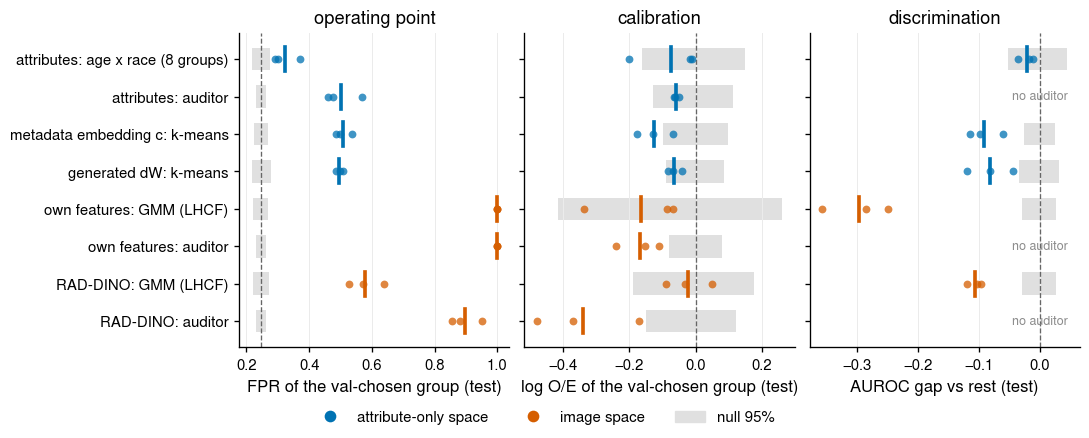

In [7]:
def draw_lenses(table, path):
    order = list(METHODS)
    fig, axes = plt.subplots(1, 3, figsize=(SLIDE_WIDTH, 3.6), sharey=True)
    references = {"operating point": OVERALL_FPR, "calibration": 0.0, "discrimination": 0.0}
    xlabels = {
        "operating point": "FPR of the val-chosen group (test)",
        "calibration": "log O/E of the val-chosen group (test)",
        "discrimination": "AUROC gap vs rest (test)",
    }
    for ax, lens in zip(axes, LENSES):
        sub = table[table.lens == lens]
        for i, method in enumerate(order):
            rows_ = sub[sub.method == method]
            if rows_.empty:
                ax.text(references[lens], i, "no auditor", ha="center", va="center", fontsize=7.5, color=NEUTRAL)
                continue
            color = ATTRIBUTE_SPACE if METHODS[method] == "attribute" else IMAGE_SPACE
            ax.add_patch(plt.Rectangle((rows_.null_low.mean(), i - 0.3), rows_.null_high.mean() - rows_.null_low.mean(), 0.6,
                                       color="0.88", lw=0, zorder=0))
            ax.scatter(rows_.value, np.full(len(rows_), i), s=22, color=color, alpha=0.75, lw=0, zorder=3)
            ax.plot([rows_.value.mean()] * 2, [i - 0.32, i + 0.32], color=color, lw=2.2, zorder=4)
        ax.axvline(references[lens], color="0.4", lw=0.8, ls="--", zorder=1)
        ax.set(title=lens, xlabel=xlabels[lens])
        ax.grid(axis="x", color="0.92")
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(range(len(order)), order)
    axes[0].invert_yaxis()
    handles = [
        Line2D([], [], color=ATTRIBUTE_SPACE, marker="o", ls="", label="attribute-only space"),
        Line2D([], [], color=IMAGE_SPACE, marker="o", ls="", label="image space"),
        plt.Rectangle((0, 0), 1, 1, color="0.88", label="null 95%"),
    ]
    fig.legend(handles=handles, loc="outside lower center", ncol=3, frameon=False)
    fig.savefig(path)
    plt.show()


draw_lenses(lenses, FIGURES / "fig2_lenses_by_method.png")

## 図 3：属性の空間の群は、陽性率で FPR が並ぶ

01 の図を 2 パネルに絞る。8 群と ΔW の k-means（K = 8）の各群を、test の陽性率と FPR で置く。点の大きさは群の件数。

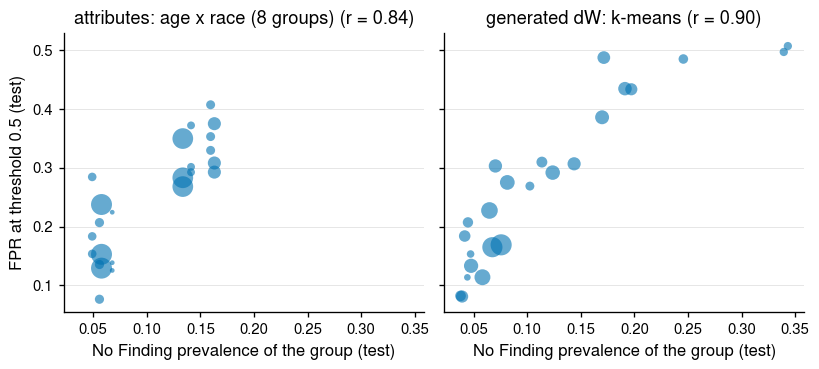

In [8]:
def prevalence_fpr_rows():
    out = []
    for seed in RUNS:
        test = DATA[seed]["test"].frame
        for name in ("attributes: age x race (8 groups)", "generated dW: k-means"):
            table = sg.group_table(CLUSTERINGS[seed][name][1], test)
            out.append(table.assign(seed=seed, method=name))
    return pd.concat(out, ignore_index=True)


def draw_prevalence_fpr(table, path):
    fig, axes = plt.subplots(1, 2, figsize=(SLIDE_WIDTH * 0.75, 3.0), sharey=True, sharex=True)
    for ax, (name, sub) in zip(axes, table.groupby("method", sort=False)):
        sub = sub.dropna(subset=["fpr"])
        r = np.corrcoef(sub.prevalence, sub.fpr)[0, 1]
        ax.scatter(sub.prevalence, sub.fpr, s=sub.n / 40, color=ATTRIBUTE_SPACE, alpha=0.6, lw=0)
        ax.set(title=f"{name} (r = {r:.2f})", xlabel="No Finding prevalence of the group (test)")
    axes[0].set_ylabel("FPR at threshold 0.5 (test)")
    fig.savefig(path)
    plt.show()


prevalence_fpr = prevalence_fpr_rows()
prevalence_fpr.to_csv(RESULTS / "prevalence_vs_fpr.csv", index=False)
draw_prevalence_fpr(prevalence_fpr, FIGURES / "fig3_prevalence_vs_fpr.png")

## RAD-DINO の監査器の群（較正で最悪）

図 2 の較正の列で突出した群を掘る。seed ごとに val で log O/E 最小の群を選び、test の行を集める。

In [9]:
AUDIT_GROUP = {}
for seed in RUNS:
    val, test = DATA[seed]["val"].frame, DATA[seed]["test"].frame
    p_val, p_test = PROB[seed]
    val_groups, test_groups = auditors(seed, "calibration")["RAD-DINO: auditor"]
    chosen = sg.calibration_table(val_groups, val.target.to_numpy(), p_val).log_oe.idxmin()
    AUDIT_GROUP[seed] = test_groups == chosen
{seed: int(mask.sum()) for seed, mask in AUDIT_GROUP.items()}

{42: 2333, 43: 2245, 44: 2341}

## 図 4：同じ得点でも、この群では No Finding が少ない

左：信頼性曲線。群と補集合のそれぞれで、再較正した確率の分位で 8 つの帯に切り、帯ごとの予測と実際を比べる（3 seed をまとめる）。
右：群の中身。全体に対する割合の比（点は 3 seed の平均、線は最小〜最大）。

In [10]:
FACTOR_LABELS = {
    "dz_Pneumothorax": "pneumothorax",
    "sternotomy": "sternotomy",
    "dz_Enlarged Cardiomediastinum": "widened mediastinum",
    "dz_Lung Lesion": "lung lesion",
    "affirmed_normal": "report affirms normal",
    "pacer": "pacemaker",
    "lateral": "lateral view",
    "young": "age < 65",
    "female": "female",
    "black": "Black",
}


def with_factors(frame):
    return frame.assign(
        young=frame.age65 == 0,
        female=frame.sex == 1,
        black=frame.race_group == 3,
        lateral=frame.view == 2,
        affirmed_normal=frame.report_type == "affirmed_normal",
    )


def reliability(y, p, bins=8):
    edges = np.quantile(p, np.linspace(0, 1, bins + 1))
    index = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    table = pd.DataFrame({"bin": index, "y": y, "p": p}).groupby("bin").agg(predicted=("p", "mean"), observed=("y", "mean"), n=("y", "size"))
    return table


reliability_rows, composition_rows = [], []
for seed, mask in AUDIT_GROUP.items():
    test = with_factors(DATA[seed]["test"].frame)
    p_test = PROB[seed][1]
    for name, rows_ in (("group", mask), ("rest", ~mask)):
        reliability_rows.append(pd.DataFrame({"set": name, "seed": seed, "y": test.target.to_numpy()[rows_], "p": p_test[rows_]}))
    for factor, label in FACTOR_LABELS.items():
        ratio = test[factor][mask].mean() / test[factor].mean()
        composition_rows.append({"seed": seed, "factor": label, "ratio": ratio})
pooled = pd.concat(reliability_rows, ignore_index=True)
curves = pd.concat([reliability(sub.y.to_numpy(), sub.p.to_numpy()).assign(set=name) for name, sub in pooled.groupby("set")])
composition = pd.DataFrame(composition_rows)
curves.to_csv(RESULTS / "auditor_group_reliability.csv")
composition.to_csv(RESULTS / "auditor_group_composition.csv", index=False)
curves.round(3)

,predicted,observed,n,set
bin,,,,
0,0.006,0.006,865,group
1,0.010,0.014,865,group
2,0.015,0.012,865,group
3,0.020,0.012,864,group
4,0.026,0.027,865,group
5,0.041,0.032,865,group
6,0.092,0.074,865,group
7,0.313,0.206,865,group
0,0.006,0.012,6492,rest


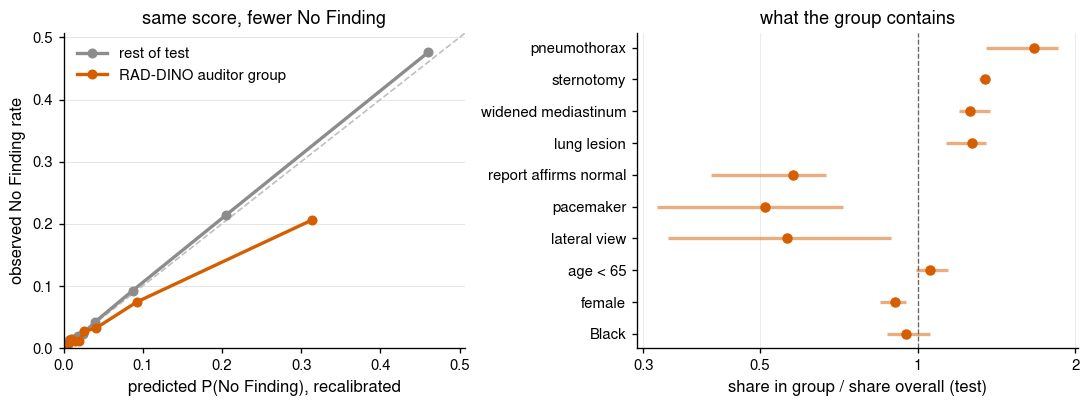

In [11]:
def draw_auditor_group(curves, composition, path):
    fig, (left, right) = plt.subplots(1, 2, figsize=(SLIDE_WIDTH, 3.3), width_ratios=[1, 1.1])
    top = curves.predicted.max() * 1.1
    left.plot([0, top], [0, top], color="0.75", lw=1, ls="--")
    for name, color, label in (("rest", NEUTRAL, "rest of test"), ("group", IMAGE_SPACE, "RAD-DINO auditor group")):
        sub = curves[curves.set == name]
        left.plot(sub.predicted, sub.observed, color=color, lw=2, marker="o", ms=5, label=label)
    left.set(xlabel="predicted P(No Finding), recalibrated", ylabel="observed No Finding rate", xlim=(0, top), ylim=(0, top),
             title="same score, fewer No Finding")
    left.legend(loc="upper left", frameon=False)

    summary = composition.groupby("factor", sort=False).ratio.agg(["mean", "min", "max"])
    y = np.arange(len(summary))
    right.hlines(y, summary["min"], summary["max"], color=IMAGE_SPACE, lw=2, alpha=0.5)
    right.scatter(summary["mean"], y, color=IMAGE_SPACE, s=30, zorder=3)
    right.axvline(1, color="0.4", lw=0.8, ls="--")
    right.set_yticks(y, summary.index)
    right.invert_yaxis()
    right.set(xscale="log", xlabel="share in group / share overall (test)", title="what the group contains")
    right.set_xticks([0.3, 0.5, 1, 2], ["0.3", "0.5", "1", "2"])
    right.set_xticks([], minor=True)
    right.grid(axis="x", color="0.92")
    right.grid(axis="y", visible=False)
    fig.savefig(path)
    plt.show()


draw_auditor_group(curves, composition, FIGURES / "fig4_auditor_group_calibration.png")

## 図 5：その群は、主指標では悪い群ではない

同じ群の FPR・TPR・AUROC を補集合と比べる（gap = 群 − 補集合）。点は seed、棒は 3 seed の平均。

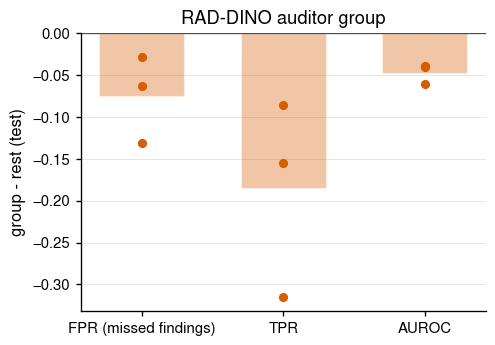

,mean,min,max
metric,,,
FPR (missed findings),-0.074,-0.132,-0.029
TPR,-0.185,-0.316,-0.085
AUROC,-0.047,-0.061,-0.039


In [12]:
gap_rows = []
for seed, mask in AUDIT_GROUP.items():
    row = sg.performance_of(mask, DATA[seed]["test"].frame, PROB[seed][1])
    gap_rows += [{"seed": seed, "metric": metric, "gap": row[f"gap_{key}"]} for metric, key in
                 (("FPR (missed findings)", "fpr"), ("TPR", "tpr"), ("AUROC", "auroc"))]
gaps = pd.DataFrame(gap_rows)
gaps.to_csv(RESULTS / "auditor_group_gaps.csv", index=False)


def draw_gaps(gaps, path):
    fig, ax = plt.subplots(figsize=(SLIDE_WIDTH * 0.45, 2.8))
    metrics = list(dict.fromkeys(gaps.metric))
    means = gaps.groupby("metric", sort=False).gap.mean()
    ax.bar(range(len(metrics)), means.loc[metrics], color=IMAGE_SPACE, alpha=0.35, width=0.6)
    for i, metric in enumerate(metrics):
        ax.scatter(np.full(3, i), gaps[gaps.metric == metric].gap, color=IMAGE_SPACE, s=22, zorder=3)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_xticks(range(len(metrics)), metrics)
    ax.set(ylabel="group - rest (test)", title="RAD-DINO auditor group")
    fig.savefig(path)
    plt.show()


draw_gaps(gaps, FIGURES / "fig5_auditor_group_gaps.png")
gaps.groupby("metric", sort=False).gap.agg(["mean", "min", "max"]).round(3)

## RAD-DINO のクラスタ（判別の悪い群）

RAD-DINO の GMM（K = 11）は学習したモデルによらないので、3 seed で同じ群になる。各クラスタの較正（log O/E）と判別（AUROC）を
3 seed で平均し、主な撮影の向きで色を分ける。クラスタ 9 は、03 で val の log O/E 最小として 3 seed とも選ばれた群。

In [13]:
VIEW_NAMES = {0: "AP", 1: "PA", 2: "lateral"}
cluster_rows = []
for seed in RUNS:
    test = DATA[seed]["test"].frame
    p_test = PROB[seed][1]
    test_groups = CLUSTERINGS[seed]["RAD-DINO: GMM (LHCF)"][1]
    for g in np.unique(test_groups):
        mask = test_groups == g
        row = sg.performance_of(mask, test, p_test)
        shares = test.view[mask].value_counts(normalize=True)
        view = VIEW_NAMES[shares.idxmax()] if shares.max() >= 0.8 else "mixed"
        cluster_rows.append({"seed": seed, "cluster": g, "view": view, "sternotomy": test.sternotomy[mask].mean(),
                             **{key: row[key] for key in ("n", "n_pos", "prevalence", "tpr", "fpr", "auroc", "log_oe")}})
clusters = pd.DataFrame(cluster_rows)
clusters.to_csv(RESULTS / "raddino_clusters_by_seed.csv", index=False)
cluster_mean = clusters.groupby(["cluster", "view"]).mean(numeric_only=True).drop(columns="seed").reset_index()
cluster_mean.round(3)

,cluster,view,sternotomy,n,n_pos,prevalence,tpr,fpr,auroc,log_oe
0,0,AP,0.007,4022.0,185.0,0.046,0.656,0.148,0.834,-0.221
1,1,AP,0.142,1377.0,93.0,0.068,0.735,0.184,0.844,-0.034
2,2,lateral,0.169,954.0,78.0,0.082,0.735,0.194,0.848,0.106
3,3,AP,0.100,40.0,3.0,0.075,NaN,0.162,NaN,0.293
4,4,PA,0.105,2363.0,470.0,0.199,0.907,0.434,0.835,0.058
5,5,AP,0.005,3716.0,520.0,0.140,0.872,0.353,0.842,0.046
6,6,mixed,0.113,592.0,69.0,0.117,0.894,0.331,0.861,-0.098
7,7,lateral,0.069,1464.0,370.0,0.253,0.943,0.580,0.804,0.131
8,8,AP,0.003,2203.0,107.0,0.049,0.645,0.124,0.797,-0.028
9,9,AP,0.427,2393.0,90.0,0.038,0.456,0.095,0.756,-0.024


## 図 6：較正は合っているが、判別の悪い群

左：11 クラスタの較正と判別（陽性 20 件未満のクラスタは AUROC を出さない）。
右：クラスタ 9 と、それ以外の AP 画像の得点（logit 差）の分布。AP 同士で比べて、撮影の向きの効果を除く（3 seed をまとめる）。

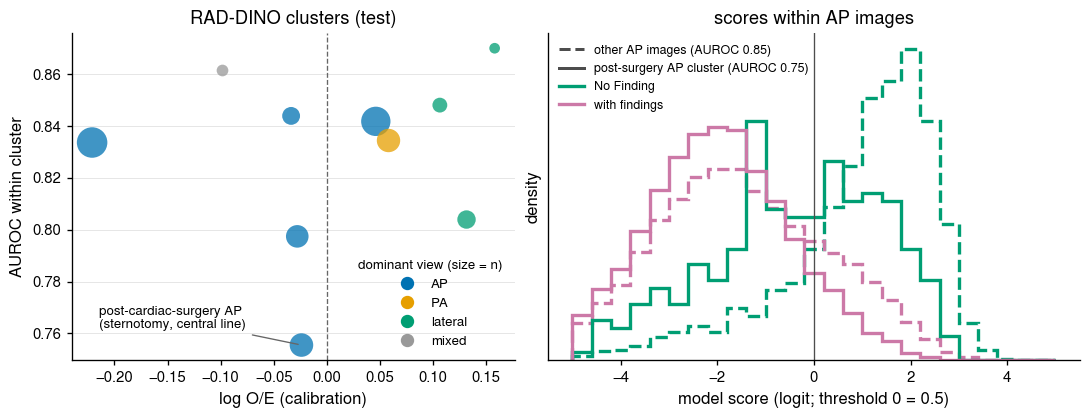

In [14]:
POST_SURGERY = 9  # 03 で 3 seed とも選ばれたクラスタ。胸骨切開・中心静脈カテーテルに富む AP 画像
VIEW_COLORS = {"AP": "#0072B2", "PA": "#E69F00", "lateral": "#009E73", "mixed": "0.6"}


def margin_rows():
    out = []
    for seed in RUNS:
        test = DATA[seed]["test"].frame
        test_groups = CLUSTERINGS[seed]["RAD-DINO: GMM (LHCF)"][1]
        ap = test.view.to_numpy() == 0
        for name, mask in (("post-surgery AP cluster", ap & (test_groups == POST_SURGERY)), ("other AP images", ap & (test_groups != POST_SURGERY))):
            out.append(pd.DataFrame({"set": name, "seed": seed, "y": test.target[mask], "margin": test.margin[mask]}))
    return pd.concat(out, ignore_index=True)


def draw_clusters(cluster_mean, margins, path):
    fig, (left, right) = plt.subplots(1, 2, figsize=(SLIDE_WIDTH, 3.4), width_ratios=[1, 1.2])
    shown = cluster_mean.dropna(subset=["auroc"])
    for view, sub in shown.groupby("view"):
        left.scatter(sub.log_oe, sub.auroc, s=sub.n / 12, color=VIEW_COLORS[view], alpha=0.75, lw=0)
    target = shown[shown.cluster == POST_SURGERY].iloc[0]
    left.annotate("post-cardiac-surgery AP\n(sternotomy, central line)", (target.log_oe, target.auroc), xytext=(-0.215, 0.762),
                  fontsize=8, arrowprops={"arrowstyle": "-", "color": "0.4", "lw": 0.8})
    left.axvline(0, color="0.4", lw=0.8, ls="--")
    left.set(xlabel="log O/E (calibration)", ylabel="AUROC within cluster", title="RAD-DINO clusters (test)")
    handles = [Line2D([], [], color=color, marker="o", ls="", ms=7, label=view) for view, color in VIEW_COLORS.items()]
    left.legend(handles=handles, title="dominant view (size = n)", frameon=False, loc="lower right", fontsize=8, title_fontsize=8)

    bins = np.linspace(-5, 5, 26)
    for name, style in (("other AP images", "--"), ("post-surgery AP cluster", "-")):
        sub = margins[margins.set == name]
        auroc = roc_auc_score(sub.y, sub.margin)
        right.hist(sub.margin[sub.y == 1], bins=bins, density=True, histtype="step", lw=2, ls=style, color=POSITIVE)
        right.hist(sub.margin[sub.y == 0], bins=bins, density=True, histtype="step", lw=2, ls=style, color=NEGATIVE)
        right.plot([], [], color="0.3", ls=style, label=f"{name} (AUROC {auroc:.2f})")
    right.plot([], [], color=POSITIVE, lw=2, label="No Finding")
    right.plot([], [], color=NEGATIVE, lw=2, label="with findings")
    right.axvline(0, color="0.3", lw=0.8)
    right.set(xlabel="model score (logit; threshold 0 = 0.5)", ylabel="density", yticks=[], title="scores within AP images")
    right.legend(frameon=False, fontsize=7.5, loc="upper left")
    fig.savefig(path)
    plt.show()


margins = margin_rows()
draw_clusters(cluster_mean, margins, FIGURES / "fig6_raddino_clusters.png")

## 図 7：小さい群は、val で見えたずれが test で戻る

03 の `granularity_sweep.csv` から、k-means の K を上げたときの、val で選んだ群の log O/E を val と test で並べる。

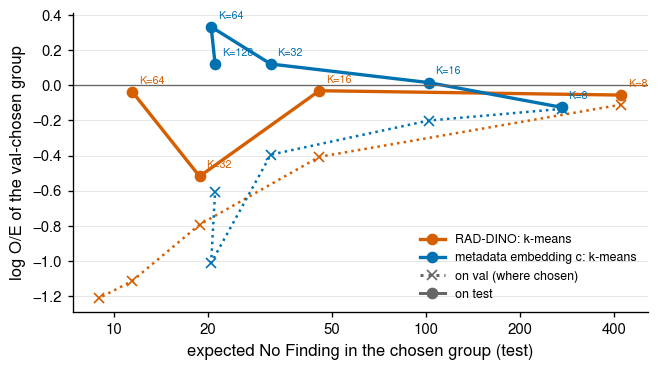

In [15]:
sweep = pd.read_csv(PACKAGE / "results" / "03_calibration_bias" / "granularity_sweep.csv")
SWEEP_LABELS = {"RAD-DINO / k-means": ("RAD-DINO: k-means", IMAGE_SPACE), "c / k-means": ("metadata embedding c: k-means", ATTRIBUTE_SPACE)}


def draw_sweep(sweep, path):
    fig, ax = plt.subplots(figsize=(SLIDE_WIDTH * 0.6, 3.0))
    for key, (label, color) in SWEEP_LABELS.items():
        sub = sweep[sweep.partition == key].groupby("setting")[["val_chosen_test_expected", "val_chosen_val_log_oe", "val_chosen_test_log_oe"]].mean()
        ax.plot(sub.val_chosen_test_expected, sub.val_chosen_val_log_oe, color=color, lw=1.5, ls=":", marker="x")
        ax.plot(sub.val_chosen_test_expected, sub.val_chosen_test_log_oe, color=color, lw=2, marker="o", label=label)
        for k, row in sub.iterrows():
            ax.annotate(f"K={k}", (row.val_chosen_test_expected, row.val_chosen_test_log_oe), xytext=(4, 5), textcoords="offset points", fontsize=6.5, color=color)
    ax.axhline(0, color="0.4", lw=0.8)
    ax.plot([], [], color="0.4", ls=":", marker="x", label="on val (where chosen)")
    ax.plot([], [], color="0.4", marker="o", label="on test")
    ax.set(xscale="log", xlabel="expected No Finding in the chosen group (test)", ylabel="log O/E of the val-chosen group")
    ax.set_xticks([10, 20, 50, 100, 200, 400], ["10", "20", "50", "100", "200", "400"])
    ax.set_xticks([], minor=True)
    ax.legend(frameon=False, fontsize=7.5, loc="lower right")
    fig.savefig(path)
    plt.show()


draw_sweep(sweep, FIGURES / "fig7_granularity.png")

## 図 8：4 つの分け方の、最悪群と gap（報告用の簡潔版）

図 2 は情報が多く説明しにくいので、分け方を 4 つに絞り、research-premises の指標をそのまま並べる。

- 分け方：属性（年齢 65 歳 × race の 8 群）、metadata embedding c・生成 ΔW・RAD-DINO の k-means（K = 8、val で当てて test に適用）
- 指標（test）：最悪 FPR（最大）、FPR gap（最大 − 最小）、最悪 AUROC（最小）、AUROC gap（最大 − 最小）
- FPR は陰性 20 件以上、AUROC は陽性・陰性とも 20 件以上の群で数える。評価できた群の数を図に添える
- 群の選択はしない（test の全群の最大・最小）。4 つとも K = 8 なので、選んだことによる偏りは同じ条件でかかる

In [16]:
SIMPLE = {
    "attributes\n(age x race)": lambda seed: CLUSTERINGS[seed]["attributes: age x race (8 groups)"][1],
    "metadata\nembedding c": lambda seed: CLUSTERINGS[seed]["metadata embedding c: k-means"][1],
    "generated\ndW": lambda seed: CLUSTERINGS[seed]["generated dW: k-means"][1],
    "RAD-DINO\nimage features": lambda seed: sg.kmeans_groups(*SPACES[seed]["rad32"], K_CLUSTER)[1],
}
simple_rows = []
for seed in RUNS:
    test = DATA[seed]["test"].frame
    y, margin = test.target.to_numpy(), test.margin.to_numpy()
    for name, groups_of in SIMPLE.items():
        groups = groups_of(seed)
        fpr = sg.group_table(groups, test).fpr.dropna()
        auroc = group_aurocs(groups, y, margin)
        simple_rows.append({"seed": seed, "partition": name, "worst FPR": fpr.max(), "FPR gap": fpr.max() - fpr.min(),
                            "worst AUROC": auroc.min(), "AUROC gap": auroc.max() - auroc.min(),
                            "groups (FPR)": len(fpr), "groups (AUROC)": len(auroc)})
simple = pd.DataFrame(simple_rows)
simple.assign(partition=simple.partition.str.replace("\n", " ")).to_csv(RESULTS / "four_partitions_by_seed.csv", index=False)
OVERALL_AUROC = np.mean([roc_auc_score(d["test"].frame.target, d["test"].frame.margin) for d in DATA.values()])
simple.groupby("partition", sort=False).mean(numeric_only=True).drop(columns="seed").round(3)

,worst FPR,FPR gap,worst AUROC,AUROC gap,groups (FPR),groups (AUROC)
partition,,,,,,
attributes\n(age x race),0.363,0.224,0.739,0.141,8.0,8.0
metadata\nembedding c,0.507,0.381,0.750,0.127,8.0,8.0
generated\ndW,0.497,0.381,0.739,0.133,8.0,8.0
RAD-DINO\nimage features,0.480,0.340,0.832,0.036,8.0,7.0


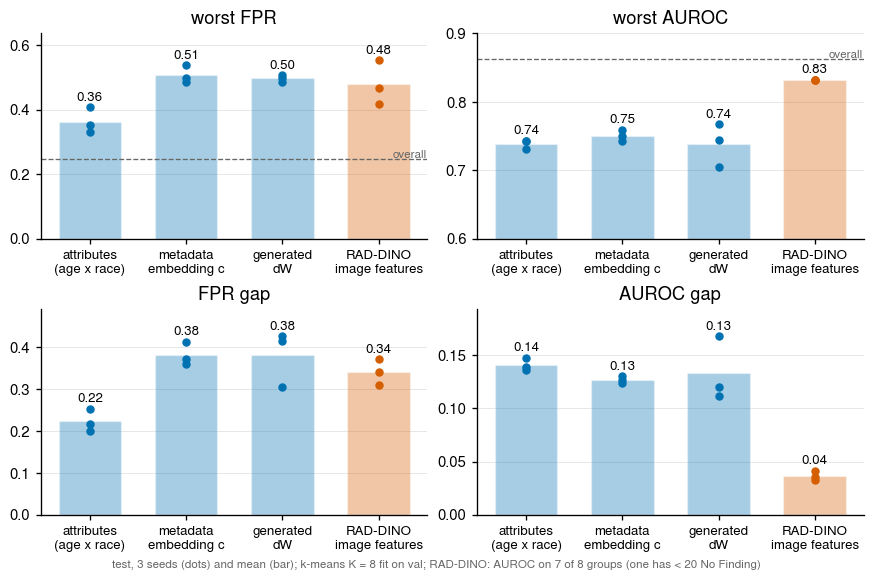

In [17]:
def draw_four_partitions(table, path):
    names = list(SIMPLE)
    colors = [ATTRIBUTE_SPACE, ATTRIBUTE_SPACE, ATTRIBUTE_SPACE, IMAGE_SPACE]
    panels = [("worst FPR", OVERALL_FPR, "overall"), ("FPR gap", None, None), ("worst AUROC", OVERALL_AUROC, "overall"), ("AUROC gap", None, None)]
    fig, axes = plt.subplots(2, 2, figsize=(SLIDE_WIDTH * 0.8, 4.6))
    axes = axes.T.ravel()
    x = np.arange(len(names))
    for ax, (metric, reference, ref_label) in zip(axes, panels):
        means = table.groupby("partition", sort=False)[metric].mean().loc[names]
        ax.bar(x, means, color=colors, alpha=0.35, width=0.65)
        for i, name in enumerate(names):
            ax.scatter(np.full(3, i), table[table.partition == name][metric], color=colors[i], s=18, zorder=3)
            top = table[table.partition == name][metric].max()
            ax.annotate(f"{means.iloc[i]:.2f}", (i, top), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)
        if reference is not None:
            ax.axhline(reference, color="0.4", lw=0.8, ls="--")
            ax.text(len(names) - 0.5, reference, ref_label, ha="right", va="bottom", fontsize=7, color="0.4")
        ax.set_xticks(x, names, fontsize=8)
        ax.margins(y=0.15)
        ax.set_title(metric)
    axes[2].set_ylim(0.6, 0.9)
    fig.text(0.5, -0.02, "test, 3 seeds (dots) and mean (bar); k-means K = 8 fit on val; RAD-DINO: AUROC on 7 of 8 groups (one has < 20 No Finding)", ha="center", fontsize=7, color="0.4")
    fig.savefig(path)
    plt.show()


draw_four_partitions(simple, FIGURES / "fig8_four_partitions.png")

## 図 9：生成 ΔW の最悪群の組成（FPR・AUROC）

図 8 の生成 ΔW（k-means、K = 8）で、test の FPR が最大の群と AUROC が最小の群が、どんな人の群かを見る。
seed ごとに群が違うので、seed ごとに 1 本の棒にし、test 全体と並べる。

- FPR が最悪：若い・外来（PA・側面）の群。陽性率が高く、陰性も 0.5 を超えやすい
- AUROC が最悪：80 歳以上・病棟（AP）の群。陽性率が約 4% で、数少ない正常を見分けられない

In [18]:
AGE_BINS = [0, 45, 65, 80, 120]
AGE_LABELS = ["< 45", "45-64", "65-79", "80+"]
COMPOSITION = {
    "age": (AGE_LABELS, ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]),
    "race": (["White", "Black", "Asian", "Others"], ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]),
    "sex": (["male", "female"], ["#0072B2", "#E69F00"]),
    "view": (["AP", "PA", "lateral"], ["#0072B2", "#E69F00", "#009E73"]),
}


def describe(frame):
    return pd.DataFrame({
        "age": pd.cut(frame.age, AGE_BINS, right=False, labels=AGE_LABELS).astype(str),
        "race": frame.race_group.map(sg.RACE_NAMES),
        "sex": np.where(frame.sex == 1, "female", "male"),
        "view": frame.view.map(VIEW_NAMES),
    })


worst_rows = []
for seed in RUNS:
    test = DATA[seed]["test"].frame
    groups = CLUSTERINGS[seed]["generated dW: k-means"][1]
    picks = {
        "worst FPR": sg.group_table(groups, test).set_index("group").fpr.idxmax(),
        "worst AUROC": group_aurocs(groups, test.target.to_numpy(), test.margin.to_numpy()).idxmin(),
    }
    people = describe(test)
    for kind, group in picks.items():
        mask = groups == group
        for factor in COMPOSITION:
            shares = people[factor][mask].value_counts(normalize=True)
            worst_rows += [{"seed": seed, "set": kind, "n": int(mask.sum()), "prevalence": test.target[mask].mean(),
                            "factor": factor, "level": level, "share": shares.get(level, 0.0)} for level in COMPOSITION[factor][0]]
    if seed == next(iter(RUNS)):
        for factor in COMPOSITION:
            shares = people[factor].value_counts(normalize=True)
            worst_rows += [{"seed": 0, "set": "all test", "n": len(test), "prevalence": test.target.mean(),
                            "factor": factor, "level": level, "share": shares.get(level, 0.0)} for level in COMPOSITION[factor][0]]
worst_composition = pd.DataFrame(worst_rows)
worst_composition.to_csv(RESULTS / "dw_worst_group_composition.csv", index=False)
worst_composition.pivot_table(index=["set", "seed", "n", "prevalence"], columns=["factor", "level"], values="share").round(2)

factor                              age                    race               \
level                             45-64 65-79   80+  < 45 Asian Black Others   
set         seed n     prevalence                                              
all test    0    19617 0.104195    0.37  0.29  0.17  0.18  0.06  0.19   0.11   
worst AUROC 42   1923  0.041602    0.00  0.35  0.65  0.00  0.00  0.02   0.07   
            43   2144  0.039179    0.00  0.14  0.86  0.00  0.05  0.23   0.11   
            44   1644  0.037713    0.00  0.03  0.97  0.00  0.06  0.06   0.10   
worst FPR   42   2345  0.171429    0.79  0.14  0.00  0.07  0.19  0.10   0.03   
            43   982   0.343177    0.07  0.00  0.00  0.93  0.09  0.26   0.06   
            44   993   0.339376    0.07  0.00  0.00  0.93  0.11  0.30   0.12   

factor                                     sex        view                
level                             White female  male    AP    PA lateral  
set         seed n     prevalence                                         
all test    0    19617 0.104195    0.64   0.41  0.59  0.72  0.13    0.15  
worst AUROC 42   1923  0.041602    0.90   0.00  1.00  1.00  0.00    0.00  
            43   2144  0.039179    0.61   0.60  0.40  0.90  0.06    0.04  
            44   1644  0.037713    0.78   0.63  0.37  0.99  0.00    0.01  
worst FPR   42   2345  0.171429    0.68   0.40  0.60  0.12  0.32    0.55  
            43   982   0.343177    0.59   0.51  0.49  0.03  0.40    0.57  
            44   993   0.339376    0.47   0.57  0.43  0.11  0.45    0.44

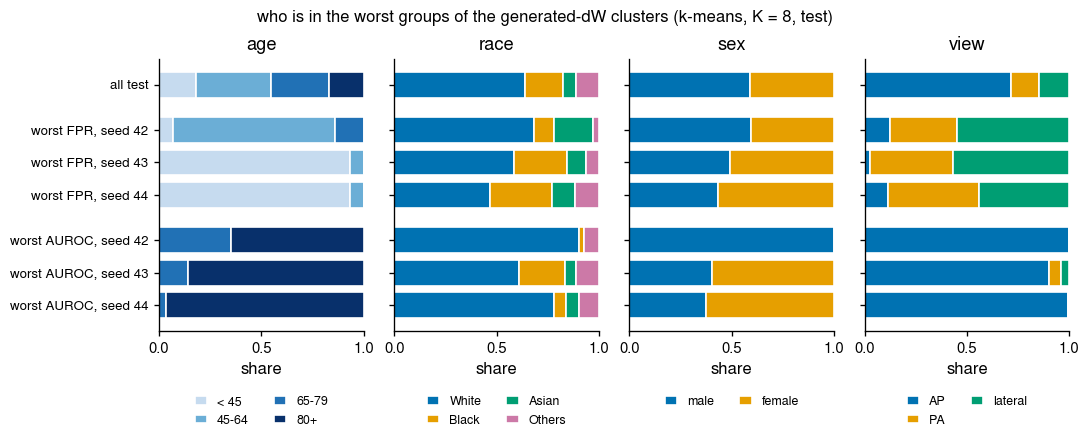

In [19]:
def draw_worst_composition(table, path):
    bars = [("all test", 0)] + [(kind, seed) for kind in ("worst FPR", "worst AUROC") for seed in RUNS]
    labels = ["all test"] + [f"{kind}, seed {seed}" for kind in ("worst FPR", "worst AUROC") for seed in RUNS]
    y = np.array([0, 1.4, 2.4, 3.4, 4.8, 5.8, 6.8])
    fig, axes = plt.subplots(1, 4, figsize=(SLIDE_WIDTH, 3.6), sharey=True)
    for ax, (factor, (levels, colors)) in zip(axes, COMPOSITION.items()):
        sub = table[table.factor == factor]
        left = np.zeros(len(bars))
        for level, color in zip(levels, colors):
            widths = np.array([sub[(sub.set == kind) & (sub.seed == seed) & (sub.level == level)].share.iloc[0] for kind, seed in bars])
            ax.barh(y, widths, left=left, color=color, height=0.8, edgecolor="white", lw=1, label=level)
            left += widths
        ax.set(xlim=(0, 1), title=factor, xlabel="share")
        ax.set_xticks([0, 0.5, 1])
        ax.grid(False)
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, fontsize=7.5, handlelength=1)
    axes[0].set_yticks(y, labels, fontsize=8)
    axes[0].invert_yaxis()
    fig.suptitle("who is in the worst groups of the generated-dW clusters (k-means, K = 8, test)", fontsize=10)
    fig.savefig(path)
    plt.show()


draw_worst_composition(worst_composition, FIGURES / "fig9_dw_worst_group_composition.png")

## 図 10：クラスタリングの結果を UMAP で描く

図 8 の k-means（K = 8）の群を、各空間の UMAP の 2 次元に描く（seed 42、test）。
群は元の空間（c の 16 次元、ΔW の kernel PCA 座標、RAD-DINO の PCA 32 次元）で作ったもので、UMAP は描くためだけに使う。
UMAP の上の距離や塊の大きさには意味を持たせない。

- c と ΔW は属性だけの関数なので、同じ属性の組み合わせ（セル）の画像は同じ点に重なる。セルごとに 1 点にし、点の大きさを件数にする
- 上段は 8 群を色分けし、下段は FPR が最悪の群と AUROC が最悪の群だけを色で示す

In [20]:
UMAP_SEED = 42
# 下段の強調色（青・朱）と混ざらないよう、上段の 8 色からは外す
CLUSTER_COLORS = ["#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#999999", "#000000", "#F0E442", "#8C564B"]
WORST_FPR_COLOR, WORST_AUROC_COLOR, OTHER_COLOR = "#D55E00", "#0072B2", "0.85"
UMAP_SPACES = {"metadata embedding c": ("c", True), "generated dW": ("dW", True), "RAD-DINO (image)": ("rad32", False)}


def umap_points(seed):
    """空間ごとに、描く点の 2 次元座標・群・件数を返す。属性だけの空間はセルごとに 1 点にまとめる。"""
    test = DATA[seed]["test"].frame
    y, margin = test.target.to_numpy(), test.margin.to_numpy()
    out = {}
    for name, (key, by_cell) in UMAP_SPACES.items():
        val_x, test_x = SPACES[seed][key]
        groups = sg.kmeans_groups(val_x, test_x, K_CLUSTER)[1]
        worst = {"fpr": sg.group_table(groups, test).set_index("group").fpr.idxmax(),
                 "auroc": group_aurocs(groups, y, margin).idxmin()}
        if by_cell:
            cells = pd.DataFrame({"cell": test.cell.to_numpy(), "group": groups})
            first = cells.groupby("cell").head(1).index.to_numpy()
            points, labels = test_x[first], groups[first]
            counts = cells.groupby("cell").size().loc[test.cell.to_numpy()[first]].to_numpy()
        else:
            points, labels, counts = test_x, groups, np.ones(len(groups))
        xy = umap.UMAP(n_neighbors=15, min_dist=0.3, random_state=0).fit_transform(points)
        out[name] = {"xy": xy, "group": labels, "count": counts, "worst": worst, "by_cell": by_cell}
    return out


UMAP_POINTS = umap_points(UMAP_SEED)
{name: (len(v["xy"]), v["worst"]) for name, v in UMAP_POINTS.items()}


def cluster_profile(seed, key):
    """k-means の各群の件数・陽性率・FPR・AUROC と、撮影の向き・80 歳以上の割合（図 10 の読み取り用）。"""
    test = DATA[seed]["test"].frame
    groups = sg.kmeans_groups(*SPACES[seed][key], K_CLUSTER)[1]
    table = sg.group_table(groups, test).set_index("group")[["n", "prevalence", "fpr"]]
    table["auroc"] = group_aurocs(groups, test.target.to_numpy(), test.margin.to_numpy())
    table["age >= 80"] = pd.Series(test.age.to_numpy() >= 80).groupby(groups).mean()
    return table.join(pd.crosstab(groups, test.view.map(VIEW_NAMES), normalize="index"))


cluster_profile(UMAP_SEED, "rad32").round(2)

/home/akiba/workspace/hypernet-fairness/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/akiba/workspace/hypernet-fairness/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/akiba/workspace/hypernet-fairness/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,n,prevalence,fpr,auroc,age >= 80,AP,PA,lateral
group,,,,,,,,
0,7586,0.07,0.24,0.84,0.16,0.98,0.02,0.00
1,2438,0.19,0.51,0.83,0.09,0.01,0.99,0.00
2,1880,0.17,0.43,0.84,0.12,0.00,0.00,1.00
3,486,0.12,0.31,0.86,0.23,0.00,0.00,1.00
4,40,0.08,0.19,NaN,0.22,0.95,0.02,0.02
5,5088,0.08,0.28,0.86,0.20,0.98,0.02,0.00
6,1546,0.06,0.18,0.86,0.28,0.97,0.02,0.00
7,553,0.24,0.55,0.85,0.11,0.00,0.02,0.97


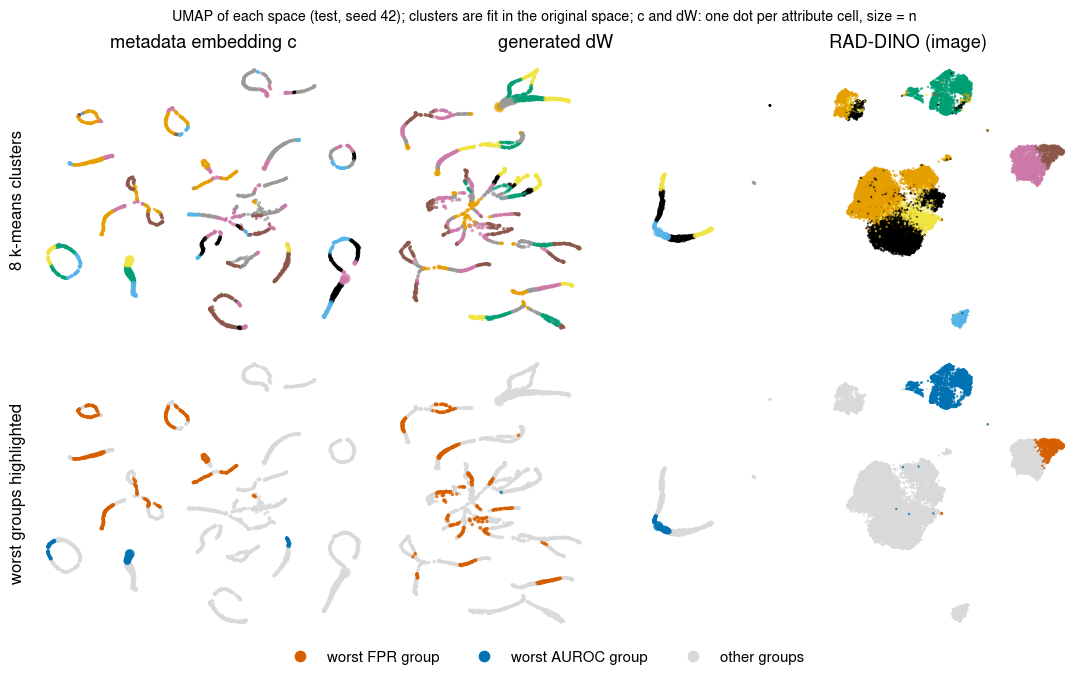

In [21]:
def point_sizes(entry):
    return 4 + entry["count"] / 8 if entry["by_cell"] else 2


def draw_umap(points, path):
    fig, axes = plt.subplots(2, 3, figsize=(SLIDE_WIDTH, 5.6))
    for column, (name, entry) in enumerate(points.items()):
        xy, groups, sizes = entry["xy"], entry["group"], point_sizes(entry)
        top, bottom = axes[0, column], axes[1, column]
        top.scatter(xy[:, 0], xy[:, 1], c=[CLUSTER_COLORS[g] for g in groups], s=sizes, alpha=0.7, lw=0)
        top.set_title(name)
        colors = np.full(len(groups), OTHER_COLOR, dtype=object)
        colors[groups == entry["worst"]["fpr"]] = WORST_FPR_COLOR
        colors[groups == entry["worst"]["auroc"]] = WORST_AUROC_COLOR
        order = np.argsort(colors != OTHER_COLOR)  # 強調する群を上に描く
        bottom.scatter(xy[order, 0], xy[order, 1], c=list(colors[order]), s=np.broadcast_to(sizes, len(groups))[order], alpha=0.8, lw=0)
        for ax in (top, bottom):
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            ax.spines[["left", "bottom"]].set_visible(False)
    axes[0, 0].set_ylabel("8 k-means clusters")
    axes[1, 0].set_ylabel("worst groups highlighted")
    handles = [Line2D([], [], color=WORST_FPR_COLOR, marker="o", ls="", label="worst FPR group"),
               Line2D([], [], color=WORST_AUROC_COLOR, marker="o", ls="", label="worst AUROC group"),
               Line2D([], [], color=OTHER_COLOR, marker="o", ls="", label="other groups")]
    fig.legend(handles=handles, loc="outside lower center", ncol=3, frameon=False)
    fig.suptitle(f"UMAP of each space (test, seed {UMAP_SEED}); clusters are fit in the original space; c and dW: one dot per attribute cell, size = n",
                 fontsize=8.5)
    fig.savefig(path)
    plt.show()


draw_umap(UMAP_POINTS, FIGURES / "fig10_umap_clusters.png")

## まとめ（数値は上の表と CSV）

- 動作点の列：属性の空間の群は 8 群より悪い FPR を示すが、陽性率で並ぶ（図 3）。画像の空間では FPR が 1 近くまで上がり、得点の高い画像を集めただけになる
- 較正の列：RAD-DINO の監査器だけが帰無分布を大きく外れる。中身は気胸・胸骨切開・縦隔拡大に寄り、属性ではほぼ決まらない（図 4）。主指標の FPR は補集合より低い（図 5）
- 判別の列：RAD-DINO のクラスタの 1 つ（術後の AP 画像）が、較正は合ったまま AUROC が低い。AP 同士で比べても低い（図 6）
- 小さい群は val で選ぶと test で戻る（図 7）